# Political Embedder Small — Latent Space & PCA Analysis

This notebook evaluates the latent embedding space of the fine-tuned `political-embedder-small` (`sentence-transformers/all-mpnet-base-v2`).

**Workflow:**
1. **Load Model**: Load the latest trained checkpoint from `models/political-embedder-small/`.
2. **Sample Data**: Sample 1,000 videos from `data/out/context.parquet` and assemble their text representation (`Channel`, `Title`, `Description`, `Tags`).
3. **Inference**: Generate dense normalized embeddings ($d=768$).
4. **Dimensionality Reduction**: Perform 2D Principal Component Analysis (PCA).
5. **Visualizations**: Project onto a 2D plane colored by **Political Slant** (left-to-right ground truth) and **Political Saliency**.

In [1]:
import sys
from pathlib import Path

# Add src directory to path
ROOT = Path("../")
sys.path.insert(0, str(ROOT / "src"))

import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer

from config import MODEL_DIR, OUT_DIR, DATA_DIR

# Aesthetics configuration
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120

/Users/gustavidunsloth/Documents/Data Science/youtube-ideology-classifier/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1023 13:21:55.377000 95909 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


## 2. Sample embeddings

In [2]:
context_path = OUT_DIR / "political_embeddings.parquet"
df = pl.read_parquet(context_path)

print(f"Sampled {len(df):,} videos.")
df.head(5)

Sampled 111,967 videos.


id,channel,title,slant,political_saliency,embedding
str,str,str,f64,f64,list[f64]
"""oWZEHs5Covo""","""Vital Information""","""The narrative is crumbling.""",-0.230769,1.0,"[0.034336, 0.079478, … -0.031161]"
"""_XOerG5R290""","""Dr. John Campbell""","""South Africa Omicron""",0.15789,0.5,"[0.030017, 0.073571, … -0.030553]"
"""rDujVSXYcrY""","""Jimmy Kimmel Live""","""President Obama Says First Lad…",-0.56098,0.5,"[0.05171, 0.05374, … -0.035399]"
"""uNXDplgft_g""","""Atun-Shei Films""","""King Philip's War: The Most Im…",-0.61644,0.8,"[0.024931, 0.067666, … -0.026831]"
"""0YCk1FyxC68""","""MyNIRS""","""Building Safeguards into Pensi…",-0.666667,0.5,"[0.006394, 0.066105, … -0.035278]"


## 4. Run 1D PCA

In [3]:
embeddings = df["embedding"].to_list()
SEED = 42
pca = PCA(n_components=1, random_state=SEED)
coords_2d = pca.fit_transform(embeddings)

var_exp = pca.explained_variance_ratio_
print(f"Explained Variance:")
print(f"  • PC1: {var_exp[0]:.2%}")
print(f"  • Total (PC1 + PC2): {sum(var_exp):.2%}")

# Merge PCA coordinates with metadata for visualization
plot_df = df.to_pandas().copy()
plot_df["pca_1"] = coords_2d[:, 0]
plot_df.head(3)

Explained Variance:
  • PC1: 41.07%
  • Total (PC1 + PC2): 41.07%


,id,channel,title,slant,political_saliency,embedding,pca_1
0,oWZEHs5Covo,Vital Information,The narrative is crumbling.,-0.230769,1.0,"[0.03433551266789436, 0.07947756350040436, 0.0...",0.060281
1,_XOerG5R290,Dr. John Campbell,South Africa Omicron,0.157890,0.5,"[0.03001725673675537, 0.07357118278741837, 0.0...",0.033739
2,rDujVSXYcrY,Jimmy Kimmel Live,President Obama Says First Lady Would Divorce ...,-0.560980,0.5,"[0.05170980468392372, 0.053739581257104874, 0....",0.196426


## 5. Visualizations on 2D Plane


In [4]:
# Sample 10,000 and attach PCA coordinates
plot_df_sample = plot_df.sample(10_000)

plot_df_sample.head()

,id,channel,title,slant,political_saliency,embedding,pca_1
22958,Cl-27JjJk-I,The Economist,Are identity politics dangerous?,-0.32075,0.8,"[0.03711899742484093, 0.060874659568071365, 0....",0.221922
1909,qy_BKKnHgas,Merrick,The IT Crowd - Fire at a Sea Parks,-0.44898,0.5,"[0.05179246515035629, 0.048300035297870636, 0....",0.108403
4261,MCDcUvsG8cs,MSNBC,The State Of American Democracy With Brian Wil...,-0.80645,1.0,"[0.039930202066898346, 0.05398567393422127, 0....",0.295317
106745,K7UXxUXASVc,Forbes Breaking News,'Do You Hold That View?': Blackburn Presses Ju...,1.00000,1.0,"[0.009433969855308533, 0.06251771003007889, 0....",-0.312200
109965,71zWFmN8GUE,SABC News,Prophet Shepherd Bushiri answers on alleged mo...,-1.00000,0.5,"[0.02859276346862316, 0.06688851118087769, 0.0...",-0.077174


### Plot A: 2D Embedding Projection Colored by Political Slant
* Blue = Left / Liberal (-1.0)
* Red = Right / Conservative (+1.0)

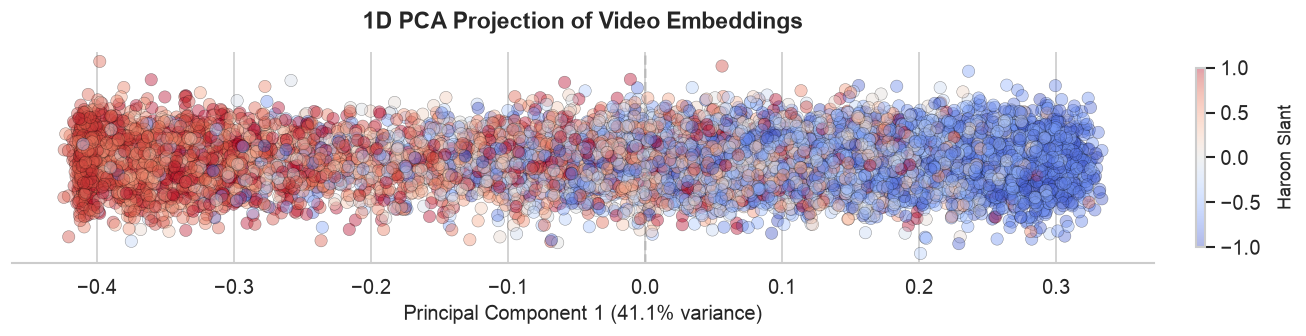

In [5]:
# 1. Reduce the height of the figure for a 1D layout (e.g., 12x3 instead of 12x8)
fig, ax = plt.subplots(figsize=(12, 3))

# 2. Create a dummy y-axis. 
y_vals = np.random.normal(loc=0, scale=0.02, size=len(plot_df_sample))

scatter = ax.scatter(
    plot_df_sample["pca_1"],
    y_vals,
    c=plot_df_sample["slant"],
    cmap="coolwarm",
    alpha=0.4,
    edgecolors="black",
    linewidth=0.3,
    s=55
)

cbar = plt.colorbar(scatter, ax=ax, shrink=0.85, pad=0.03)
cbar.set_label("Haroon Slant", fontsize=11, labelpad=10)

ax.set_title(
    f"1D PCA Projection of Video Embeddings",
    fontsize=14,
    fontweight="bold",
    pad=14
)
ax.set_xlabel(f"Principal Component 1 ({var_exp[0]:.1%} variance)", fontsize=12)

# 3. Clean up the plot by hiding the meaningless y-axis and top/side borders
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

# Keep the vertical origin line to show the center of the PCA space
ax.axvline(0, color="grey", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Plot C: Highlight Top News / Commentary Channels
Check how specific prominent media channels distribute across the learned latent space.

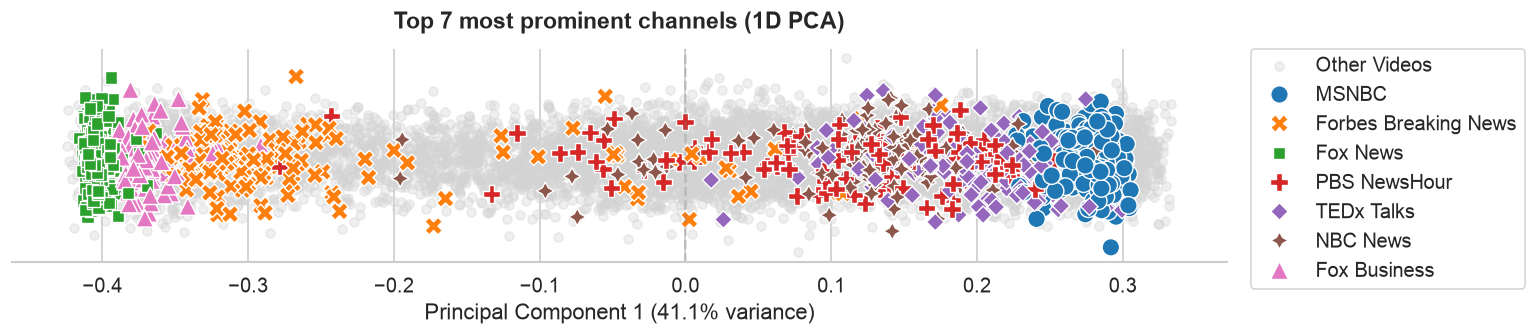

In [6]:
# 1. Assign the jitter directly to the main dataframe first
plot_df_sample["y_jitter"] = np.random.normal(loc=0, scale=0.02, size=len(plot_df_sample))

# 2. Identify top channels and create the subset (it now includes 'y_jitter')
top_channels = plot_df_sample["channel"].value_counts().head(7).index.tolist()
subset_df = plot_df_sample[plot_df_sample["channel"].isin(top_channels)]

# Use a shorter figure height for a 1D layout
fig, ax = plt.subplots(figsize=(13, 3))

# Background: all points in faint grey using the new jitter column
ax.scatter(
    plot_df_sample["pca_1"],
    plot_df_sample["y_jitter"],
    color="lightgrey",
    alpha=0.35,
    s=30,
    label="Other Videos"
)

# Foreground: top channels using the string column name so Seaborn parses it correctly
import seaborn as sns
sns.scatterplot(
    data=subset_df,
    x="pca_1",
    y="y_jitter",
    hue="channel",
    style="channel",
    s=110,
    ax=ax,
    palette="tab10"
)

ax.set_title(
    "Top 7 most prominent channels (1D PCA)",
    fontsize=14,
    fontweight="bold",
    pad=12
)
ax.set_xlabel(f"Principal Component 1 ({var_exp[0]:.1%} variance)")
ax.set_ylabel("")

# Clean up the meaningless y-axis for a 1D plot
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)

# Add origin line
ax.axvline(0, color="grey", linestyle="--", alpha=0.3)

# Legend placement
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0.)

plt.tight_layout()
plt.show()

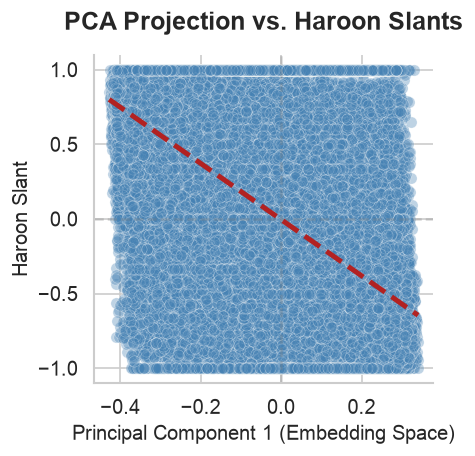

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4, 4))

sns.regplot(
    data=plot_df, 
    x="pca_1", 
    y="slant",
    ax=ax,
    # Style the background data points
    scatter_kws={
        "alpha": 0.35,         
        "s": 45,               
        "color": "steelblue",  
        "edgecolor": "white",  # Changed to singular for Seaborn compatibility
        "linewidths": 0.4      # Changed to plural for Matplotlib compatibility
    },
    # Style the regression line and confidence interval
    line_kws={
        "color": "firebrick",  
        "linewidth": 3.0,      # line_kws uses the standard singular 'linewidth'
        "linestyle": "--",     
        "zorder": 5            
    }
)

ax.set_title(
    "PCA Projection vs. Haroon Slants",
    fontsize=15, 
    fontweight="bold", 
    pad=15
)
ax.set_xlabel("Principal Component 1 (Embedding Space)", fontsize=12)
ax.set_ylabel("Haroon Slant", fontsize=12)

# Reference lines for the ideological center
ax.axhline(0, color="grey", linestyle="--", alpha=0.3, zorder=1)
ax.axvline(0, color="grey", linestyle="--", alpha=0.3, zorder=1)

# Remove harsh borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [8]:
from scipy.stats import pearsonr

# Drop nulls if any exist, as scipy cannot handle NaN values
clean_df = plot_df.dropna(subset=["pca_1", "slant"])

corr, p_value = pearsonr(clean_df["pca_1"], clean_df["slant"])

print(f"Pearson Correlation: {corr:.4f}")
print(f"P-value: {p_value:.4e}")


Pearson Correlation: -0.6636
P-value: 0.0000e+00


## 6. Inspect Extreme Videos Along Principal Component 1
Display the top videos with the lowest and highest PC1 values to inspect what semantic or ideological feature PC1 represents.

In [9]:
print("=== Lowest PC1 Values ===")
display(
    plot_df.sort_values("pca_1")
    [["channel", "title", "slant", "political_saliency", "pca_1"]]
    .head(5)
)

print("\n=== Highest PC1 Values ===")
display(
    plot_df.sort_values("pca_1", ascending=False)
    [["channel", "title", "slant", "political_saliency", "pca_1"]]
    .head(5)
)

=== Lowest PC1 Values ===


,channel,title,slant,political_saliency,pca_1
32279,Michael Knowles,WATCH Stunned Bill Maher: Guest ATTACKS Gina C...,0.85321,1.0,-0.427386
104504,Michael Knowles,Michael Knowles GOES OFF on Megan Rapinoe's Vi...,0.80952,1.0,-0.425430
61568,StevenCrowder,UNDERCOVER IN ANTIFA: Their Tactics and Media ...,0.92760,1.0,-0.424879
101268,Michael Knowles,WATCH: Hispanic Trump Supporter Asks White Lib...,0.89831,1.0,-0.424839
24227,Michael Knowles,LOL: Viral FAT Positive Activist Goes COMPLETE...,1.00000,1.0,-0.424618



=== Highest PC1 Values ===


,channel,title,slant,political_saliency,pca_1
94392,Barnard Center for Research on Women,Invisible No More: Police Responses to Violence,-1.00000,1.0,0.340552
63666,LWT,Patrisse Cullors | Fighting Systemic Racism Wh...,-0.94737,1.0,0.340136
55141,Nomiki Konst,#FemFriday - w/ Astra Taylor + Jamie Peck + Ha...,-0.82741,1.0,0.339418
2310,The Majority Report w/ Sam Seder,MyPillow Guy's Totally Sane Claim Of 'Evidence...,-0.88889,1.0,0.339210
106001,Secular Talk,Amazon Workers Denied Sick Leave DIE On The Jo...,-0.93421,1.0,0.338895


## Comparison to human labelers

In [10]:
human_labels = pd.read_pickle(DATA_DIR / "human_labels" / "human_labels.pkl")
vid_metadata = pd.read_parquet(DATA_DIR / "human_labels" / "vid_metadata.parquet")
human_labels.head()

,unique_ID,category_name,human_label,coder_id,label_timestamp,top_video_id,bottom_video_id,text,missing,top_video_score,label_x,bottom_video_score,label_y,pred_label,agree,dist
0,1025,Indicate which video is more liberal,bot,8,1630462269,5HK1hFUD_d4,QPVA8HH7l1w,Bernie Sanders criticizes Republicans,0,0.069350,0.0,0.172845,0.0,top,False,0.103495
1,1112,Indicate which video is more liberal,top,8,1630462309,npAKW_HPnq8,AK4_ogsh0Po,AOC endorsing Bernie Sanders for President,0,-0.043727,0.0,0.016742,0.0,top,True,0.060470
2,1029,Indicate which video is more liberal,bot,8,1630467371,Ib1nTc7859Y,_TgcOISrlqE,Questioning the efficacy of 'antifa violence',0,-0.063952,0.0,0.058872,0.0,top,False,0.122824
3,1061,Indicate which video is more liberal,bot,8,1630467386,KC-JiXnQSUA,JkxW7ecWl-o,Satirical video mocking Trump,0,0.092583,0.0,0.161664,0.0,top,False,0.069081
4,1070,Indicate which video is more liberal,bot,8,1630467421,SvjTeuSKTW0,iEWqEtnLLEo,Video about Jill Stein,0,0.028194,0.0,-0.052558,0.0,bot,True,0.080752


In [11]:
vid_metadata.head()

,id,text
0,vipqI7SCgjA,Channel: The Damage Report \n Title: Trump Get...
1,q5Gr9SQmkfc,Channel: Marfoogle News \n Title: THEY DONT WA...
2,fyF1pepEpDE,Channel: The Jimmy Dore Show \n Title: Justice...
3,QPVA8HH7l1w,Channel: The Damage Report \n Title: Bernie SL...
4,AK4_ogsh0Po,Channel: VICE News \n Title: This Private Scho...


In [12]:
human_labels_merged = human_labels.merge(
    vid_metadata.rename(columns={"id": "top_video_id", "text": "top_video_text"}), 
    on="top_video_id", 
    how="left"
)

human_labels_merged = human_labels_merged.merge(
    vid_metadata.rename(columns={"id": "bottom_video_id", "text": "bottom_video_text"}), 
    on="bottom_video_id", 
    how="left"
)

In [13]:
human_labels_merged.head()

,unique_ID,category_name,human_label,coder_id,label_timestamp,top_video_id,bottom_video_id,text,missing,top_video_score,label_x,bottom_video_score,label_y,pred_label,agree,dist,top_video_text,bottom_video_text
0,1025,Indicate which video is more liberal,bot,8,1630462269,5HK1hFUD_d4,QPVA8HH7l1w,Bernie Sanders criticizes Republicans,0,0.069350,0.0,0.172845,0.0,top,False,0.103495,Channel: Rob Trent \n Title: Social justice wa...,Channel: The Damage Report \n Title: Bernie SL...
1,1112,Indicate which video is more liberal,top,8,1630462309,npAKW_HPnq8,AK4_ogsh0Po,AOC endorsing Bernie Sanders for President,0,-0.043727,0.0,0.016742,0.0,top,True,0.060470,Channel: The Damage Report \n Title: AOC Offic...,Channel: VICE News \n Title: This Private Scho...
2,1029,Indicate which video is more liberal,bot,8,1630467371,Ib1nTc7859Y,_TgcOISrlqE,Questioning the efficacy of 'antifa violence',0,-0.063952,0.0,0.058872,0.0,top,False,0.122824,Channel: The Hill \n Title: Krystal Ball: 'Ber...,Channel: The Jimmy Dore Show \n Title: Is Anti...
3,1061,Indicate which video is more liberal,bot,8,1630467386,KC-JiXnQSUA,JkxW7ecWl-o,Satirical video mocking Trump,0,0.092583,0.0,0.161664,0.0,top,False,0.069081,Channel: David Pakman Show \n Title: Trump Sen...,Channel: The Young Turks \n Title: Trump: Are ...
4,1070,Indicate which video is more liberal,bot,8,1630467421,SvjTeuSKTW0,iEWqEtnLLEo,Video about Jill Stein,0,0.028194,0.0,-0.052558,0.0,bot,True,0.080752,Channel: Robert Stuart \n Title: Fabrication i...,Channel: Primo Radical \n Title: 172. Jill Ste...


Load model

In [14]:
from sentence_transformers import SentenceTransformer
import torch

model_dir = MODEL_DIR / "political-embedder-small"
device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")

# Identify latest checkpoint directory
checkpoints = sorted(
    [d for d in model_dir.glob("checkpoint-*") if d.is_dir()],
    key=lambda p: int(p.name.split("-")[1]) if p.name.split("-")[1].isdigit() else 0
)
model_path = checkpoints[-1] if checkpoints else model_dir
print(f"Loading checkpoint from: {model_path}")

model = SentenceTransformer(str(model_path), device=device)
print(f"Model successfully loaded on {device}. Embedding dimension: {model.get_sentence_embedding_dimension()}")

This model was created with Sentence Transformers version 6.2.0, but you're using version 6.1.0. Consider updating to the latest version to avoid potential issues.


Loading checkpoint from: /Users/gustavidunsloth/Documents/Data Science/youtube-ideology-classifier/nbs/../models/political-embedder-small/checkpoint-2653


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7394.48it/s]


Model successfully loaded on mps. Embedding dimension: 768


/var/folders/p6/8cdyrdjx0bb9nc27_9f01gpw0000gn/T/ipykernel_95909/2584573784.py:16: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Model successfully loaded on {device}. Embedding dimension: {model.get_sentence_embedding_dimension()}")


In [15]:
top_texts = human_labels_merged["top_video_text"].fillna("").astype(str).to_list()
bottom_texts = human_labels_merged["bottom_video_text"].fillna("").astype(str).to_list()

top_embeddings = model.encode(
    top_texts,
    batch_size=128,
    show_progress_bar=True,
    normalize_embeddings=True
)

bottom_embeddings = model.encode(
    bottom_texts,
    batch_size=128,
    show_progress_bar=True,
    normalize_embeddings=True
)


Batches:   0%|          | 0/33 [00:00<?, ?it/s]

Batches: 100%|██████████| 33/33 [01:16<00:00,  2.31s/it]


In [16]:
human_labels_merged["bottom_embeddings"] = bottom_embeddings.tolist()
human_labels_merged["top_embeddings"] = top_embeddings.tolist()

In [17]:
bottom_matrix = np.vstack(human_labels_merged["bottom_embeddings"])
top_matrix = np.vstack(human_labels_merged["top_embeddings"])

# 2. Transform all embeddings at once and flatten back to 1D arrays/lists
human_labels_merged["bottom_video_score"] = pca.transform(bottom_matrix).flatten()
human_labels_merged["top_video_score"] = pca.transform(top_matrix).flatten()

human_labels_merged["top_video_score"] = -human_labels_merged["top_video_score"]
human_labels_merged["bottom_video_score"] = -human_labels_merged["bottom_video_score"]


In [18]:
human_labels_merged["bottom_video_score"]

0      -0.312217
1      -0.290758
2      -0.306911
3      -0.276075
4      -0.279203
          ...   
4147   -0.087383
4148    0.180555
4149   -0.313939
4150   -0.265506
4151   -0.311780
Name: bottom_video_score, Length: 4152, dtype: float64

In [19]:
def label_pred(row):
    if row["category_name"] == "Indicate which video is more conservative":
        if row["top_video_score"] > row["bottom_video_score"]: return "top"
        else: return "bot"
    else:
        if row["top_video_score"] > row["bottom_video_score"]: return "bot"
        else: return "top"

human_labels_merged["pred_label"] = human_labels_merged.apply(label_pred, axis=1)
human_labels_merged["agree"] = human_labels_merged.apply(lambda row: True if row["pred_label"] == row["human_label"] else False, axis=1)
human_labels_merged["dist"] = human_labels_merged.apply(lambda row: abs(row["top_video_score"] - row["bottom_video_score"]), axis=1)

In [20]:
from sklearn.metrics import classification_report

print(classification_report(human_labels_merged["human_label"], human_labels_merged["pred_label"]))

              precision    recall  f1-score   support

         bot       0.71      0.69      0.70      2050
         top       0.71      0.73      0.72      2102

    accuracy                           0.71      4152
   macro avg       0.71      0.71      0.71      4152
weighted avg       0.71      0.71      0.71      4152



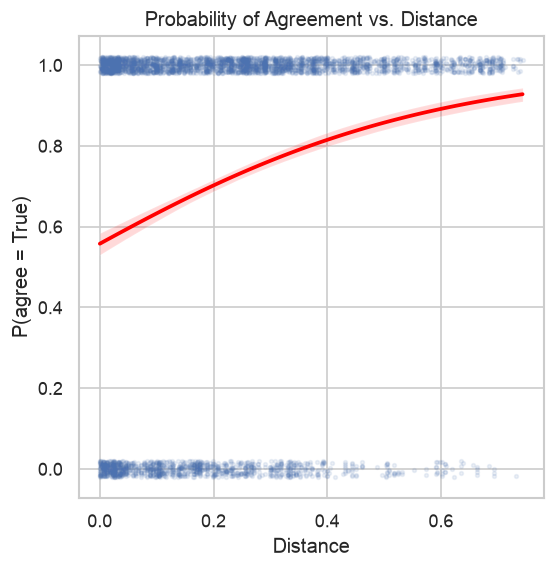

In [21]:
import matplotlib.pyplot as plt
import matplotlib as mpl

plt.figure(figsize=(5, 5))
sns.set_theme(style="whitegrid")

sns.regplot(
    data=human_labels_merged,
    x="dist",
    y="agree",
    logistic=True,
    ci=95,
    scatter_kws={"s": 5, "alpha": 0.1},
    line_kws={"color": "red"},
    y_jitter=0.02,
)

plt.title("Probability of Agreement vs. Distance")
plt.ylabel("P(agree = True)")
plt.xlabel("Distance")
plt.show()